# Room Occupancy Estimation — Notebook 02: Model Training and Evaluation

**Course:** AIML ZG565 Machine Learning — Assignment 2

**What this notebook does (assignment Step 2 and Step 3):**
1. Prepare the data (features X and target y) using the decisions from Notebook 01
2. Split into training and test sets (stratified) and save **`test_data.csv`** for the Streamlit app
3. Train the 5 required models: Logistic Regression, Decision Tree, KNN, Naive Bayes, SVM
4. Evaluate each with the 6 required metrics: Accuracy, AUC, Precision, Recall, F1, MCC
5. Compare the models and save them to the **`model/`** folder

In [1]:
# Imports
import pandas as pd                 # tables

# Paths and column names (same decisions as Notebook 01)
DATA_PATH = "../data/Occupancy_Estimation.csv"
TARGET = "Room_Occupancy_Count"     # what we predict: 0, 1, 2 or 3 people
DROP_COLS = ["Date", "Time"]        # time stamps, not sensor readings

# Load the data
df = pd.read_csv(DATA_PATH)

# X = the 16 sensor features, y = the target
X = df.drop(columns=DROP_COLS + [TARGET])
y = df[TARGET]

print("X shape:", X.shape)          # rows, features
print("y shape:", y.shape)          # rows
print("\nFeatures used:", list(X.columns))

X shape: (10129, 16)
y shape: (10129,)

Features used: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


## 1. Train / test split

- **80 % training / 20 % test**, with `stratify=y` so every class keeps its share in both sets
  (important because 81 % of rows are class 0).
- `random_state=42` makes the split reproducible (same result locally and on BITS Lab).
- The test set (features **and** target) is saved as **`test_data.csv`** in the project root —
  this is the file uploaded to the Streamlit app. The models never see it during training.

In [2]:
from sklearn.model_selection import train_test_split

# 80/20 split, keeping the class proportions equal in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,        # 20% of rows go to the test set
    stratify=y,            # same class shares in train and test
    random_state=42        # same split every time we run
)

print("Training set:", X_train.shape)
print("Test set:    ", X_test.shape)

# Check the class shares are (almost) identical in both sets
shares = pd.DataFrame({
    "train %": (y_train.value_counts(normalize=True).sort_index() * 100).round(1),
    "test %":  (y_test.value_counts(normalize=True).sort_index() * 100).round(1),
    "test rows": y_test.value_counts().sort_index(),
})
print(shares)

# Save the test set (features + target) for the Streamlit app
test_data = X_test.copy()
test_data[TARGET] = y_test
test_data.to_csv("../test_data.csv", index=False)     # ../ = project root
print("\nSaved test_data.csv:", test_data.shape)

Training set: (8103, 16)
Test set:     (2026, 16)
                      train %  test %  test rows
Room_Occupancy_Count                            
0                        81.2    81.2       1646
1                         4.5     4.5         92
2                         7.4     7.4        149
3                         6.8     6.9        139

Saved test_data.csv: (2026, 17)


## 2. The five models

Each model is a **Pipeline: StandardScaler → classifier**, so scaling is learned from the training
data only and is saved together with the model (the Streamlit app can then use raw test data).

| Model | Idea (course module) | Settings |
|---|---|---|
| Logistic Regression | linear model + softmax probabilities (M4) | `max_iter=1000` so the optimiser converges |
| Decision Tree | if-then splits on one feature at a time (M5) | default, `random_state=42` |
| K-Nearest Neighbors | vote of the 5 closest training readings (M6) | `n_neighbors=5` |
| Naive Bayes (Gaussian) | Bayes rule, features assumed independent (M8) | Gaussian, because features are continuous and can be negative |
| Support Vector Machine | maximum-margin boundary with RBF kernel (M7) | wrapped in `CalibratedClassifierCV` to get probabilities for AUC |

**Note on SVM:** an SVM outputs scores, not probabilities. AUC needs probabilities, so we wrap it in
`CalibratedClassifierCV(..., ensemble=False)` — the method recommended in scikit-learn 1.9
(the older `SVC(probability=True)` is deprecated).

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV

def make_pipeline(classifier):
    """Scaler + classifier in one object, so scaling is always applied the same way."""
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", classifier),
    ])

# The 5 required models (dictionary: display name -> pipeline)
models = {
    "Logistic Regression": make_pipeline(LogisticRegression(max_iter=1000)),
    "Decision Tree":       make_pipeline(DecisionTreeClassifier(random_state=42)),
    "KNN":                 make_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes":         make_pipeline(GaussianNB()),
    "SVM":                 make_pipeline(CalibratedClassifierCV(SVC(random_state=42), ensemble=False)),
}

for name, pipe in models.items():
    print(f"{name:20s} -> {pipe.named_steps['model']}")

Logistic Regression  -> LogisticRegression(max_iter=1000)
Decision Tree        -> DecisionTreeClassifier(random_state=42)
KNN                  -> KNeighborsClassifier()
Naive Bayes          -> GaussianNB()
SVM                  -> CalibratedClassifierCV(ensemble=False, estimator=SVC(random_state=42))


## 3. Evaluation metrics

The assignment requires 6 metrics. Because this is a **4-class** problem with imbalanced classes,
Precision, Recall and F1 are **macro-averaged**: computed for each class separately, then averaged,
so the small classes (1, 2, 3 people) count as much as the large class 0.

| Metric | Meaning | Multi-class setting |
|---|---|---|
| Accuracy | share of all predictions that are correct | — |
| AUC | how well the predicted probabilities rank the true class above the others (0.5 = random, 1 = perfect) | one-vs-rest, macro average |
| Precision | of the rows predicted as a class, how many really are that class | macro |
| Recall | of the rows that really are a class, how many were found | macro |
| F1 | harmonic mean of precision and recall | macro |
| MCC | correlation between true and predicted classes (−1 to +1, 0 = no better than chance); robust to imbalance | multi-class MCC |

In [4]:
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score,
                             recall_score, f1_score, matthews_corrcoef)
from sklearn.dummy import DummyClassifier

def evaluate(model, X, y):
    """Return the 6 required metrics for a trained model on data X with true labels y."""
    y_pred = model.predict(X)              # predicted class for every row
    y_prob = model.predict_proba(X)        # predicted probability of each class (needed for AUC)
    return {
        "Accuracy":  accuracy_score(y, y_pred),
        "AUC":       roc_auc_score(y, y_prob, multi_class="ovr", average="macro"),
        "Precision": precision_score(y, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y, y_pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y, y_pred),
    }

# Sanity check with a useless "model" that always predicts the most common class (0 people)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print("Baseline (always '0 people'):")
for metric, value in evaluate(baseline, X_test, y_test).items():
    print(f"  {metric:10s} {value:.4f}")

Baseline (always '0 people'):
  Accuracy   0.8124
  AUC        0.5000
  Precision  0.2031
  Recall     0.2500
  F1         0.2241
  MCC        0.0000


## 4. Train and evaluate the five models

Each pipeline is trained on the **training set** only and evaluated on the **held-out test set**
with the 6 metrics. Training time is recorded as extra information.

In [5]:
import time

results = []                                   # one row of metrics per model

for name, pipe in models.items():
    start = time.time()
    pipe.fit(X_train, y_train)                 # learn from the training data only
    train_seconds = time.time() - start

    scores = evaluate(pipe, X_test, y_test)    # 6 metrics on unseen test data
    scores["Train time (s)"] = train_seconds
    results.append({"ML Model Name": name, **scores})
    print(f"Trained {name:20s} in {train_seconds:.2f} s")

# Comparison table (README section d)
comparison = pd.DataFrame(results).set_index("ML Model Name")
comparison.round(4)

Trained Logistic Regression  in 0.17 s
Trained Decision Tree        in 0.04 s
Trained KNN                  in 0.02 s
Trained Naive Bayes          in 0.01 s
Trained SVM                  in 1.83 s


,Accuracy,AUC,Precision,Recall,F1,MCC,Train time (s)
ML Model Name,,,,,,,
Logistic Regression,0.9946,0.9996,0.9850,0.9803,0.9822,0.9834,0.1661
Decision Tree,0.9961,0.9929,0.9871,0.9874,0.9871,0.9880,0.0376
KNN,0.9951,0.9979,0.9823,0.9845,0.9833,0.9850,0.0181
Naive Bayes,0.9615,0.9931,0.8809,0.8880,0.8821,0.8844,0.0130
SVM,0.9970,0.9988,0.9898,0.9925,0.9911,0.9910,1.8266


## 5. Where do the models make mistakes? — Confusion matrices

Rows = true number of people, columns = predicted number. The diagonal holds correct predictions;
everything off the diagonal is a mistake.

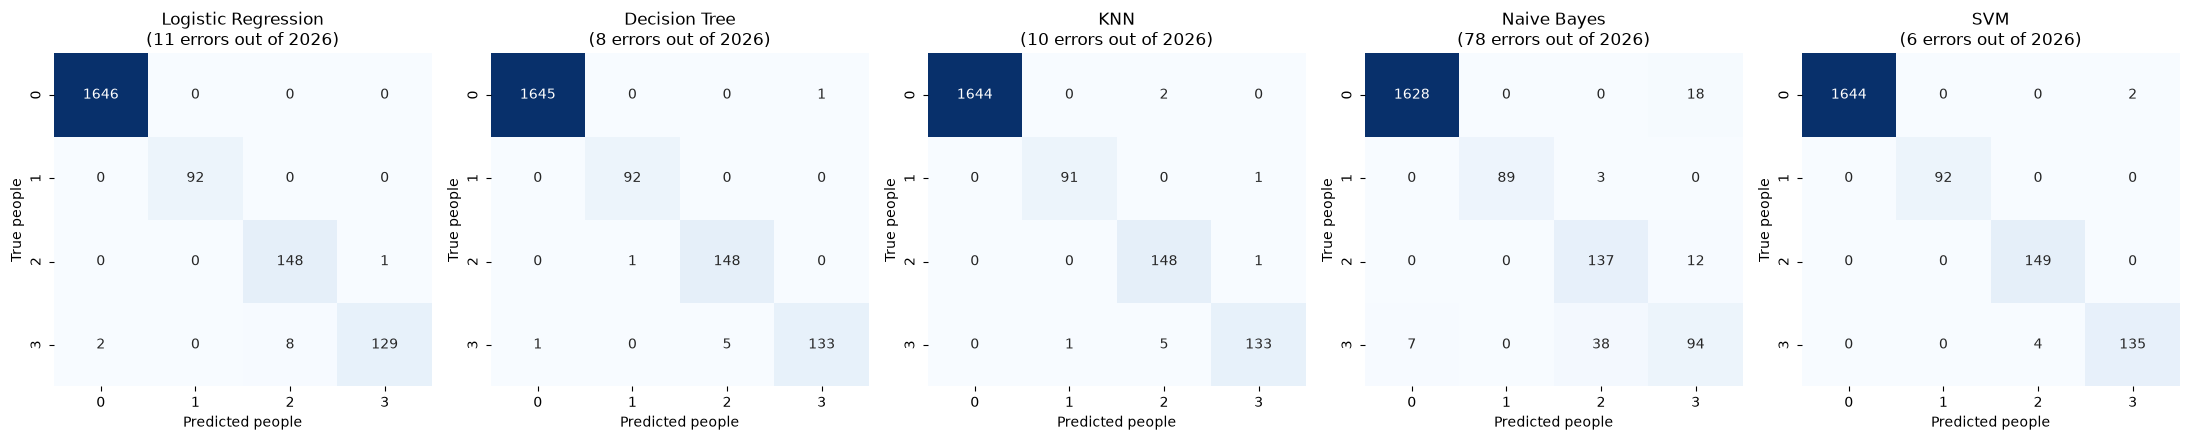

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

labels = [0, 1, 2, 3]                                  # class order for rows/columns

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (name, pipe) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test), labels=labels)
    errors = cm.sum() - cm.trace()                     # trace = sum of the diagonal (correct)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name}\n({errors} errors out of {cm.sum()})")
    ax.set_xlabel("Predicted people")
    ax.set_ylabel("True people")
plt.tight_layout()
plt.show()

**Findings (confusion matrices)**
- Empty room (0) and 1 person are classified almost perfectly by every model.
- The main error for every model is **3 people predicted as 2** (LR 8, DT 5, KNN 5, SVM 4, NB 38):
  the sensor readings for 2 and 3 people overlap (seen in Notebook 01).
- **Naive Bayes** also predicts **18 empty-room readings as 3 people** — lingering CO2 and warm
  temperatures outweigh "lights off, no motion" when features are treated as independent.
- **SVM** makes the fewest mistakes: 6 of 2,026 test rows.

## 6. Save the trained models

Each trained pipeline (scaler + model) is saved to **`model/`** with `joblib`. The Streamlit app
loads these files and only calls `predict` — it never retrains on the uploaded data.

In [7]:
import os
import joblib

MODEL_DIR = "../model"                     # project-root/model
os.makedirs(MODEL_DIR, exist_ok=True)      # create the folder if it doesn't exist

for name, pipe in models.items():
    file_name = name.lower().replace(" ", "_") + ".joblib"     # e.g. "logistic_regression.joblib"
    path = os.path.join(MODEL_DIR, file_name)
    joblib.dump(pipe, path)
    print(f"Saved {name:20s} -> model/{file_name}  ({os.path.getsize(path) / 1024:.0f} KB)")

# Check: reload one model from disk and confirm it gives the same score
reloaded = joblib.load(os.path.join(MODEL_DIR, "svm.joblib"))
print("\nReloaded SVM F1:", round(evaluate(reloaded, X_test, y_test)["F1"], 4))

Saved Logistic Regression  -> model/logistic_regression.joblib  (3 KB)
Saved Decision Tree        -> model/decision_tree.joblib  (11 KB)
Saved KNN                  -> model/knn.joblib  (1078 KB)
Saved Naive Bayes          -> model/naive_bayes.joblib  (3 KB)
Saved SVM                  -> model/svm.joblib  (105 KB)

Reloaded SVM F1: 0.9911


## 7. Comparison and observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Accuracy 0.9946, F1 0.9822, MCC 0.9834, and the **highest AUC (0.9996)** — its probabilities rank the classes very well. As a linear model it makes 11 mistakes, mostly 3 people predicted as 2 (8 of 11), where the sensor readings overlap non-linearly. |
| Decision Tree | Second-best F1 (0.9871) and MCC (0.9880) with only 8 errors, and very fast to train. It has the **lowest AUC (0.9929)** because a single tree gives "hard" leaf probabilities (mostly 0 or 1), so it ranks rows less smoothly. A fully grown tree may overfit on new data. |
| KNN | Strong results (F1 0.9833, MCC 0.9850, 10 errors) because readings taken 30 s apart are very similar, so near neighbours share the label. It needs scaled features, and as a lazy learner it stores the whole training set (largest model file, ~1 MB) and is slower at prediction time. |
| Naive Bayes | **Weakest model** (F1 0.8821, MCC 0.8844, 78 errors). Its independence assumption is broken by highly correlated sensors (temperatures up to r = 0.95), so evidence is counted several times. It confuses 3 people with 2 (38 cases) and calls 18 empty-room readings "3 people" (lingering CO2). Its accuracy (0.9615) still looks high, showing why accuracy alone misleads on imbalanced data. |
| Support Vector Machine | **Best on almost every metric**: Accuracy 0.9970, F1 0.9911, MCC 0.9910, only 6 errors. The RBF kernel captures the non-linear overlap between 2 and 3 people. It is the slowest to train (1.8 s), which is still negligible for this data size. |
| **Overall winner** | **SVM** — highest Accuracy, Recall, F1 and MCC with the fewest errors. Decision Tree is a close, faster and more interpretable alternative. All models except Naive Bayes reach F1 > 0.98. |

**Caveat:** readings are taken every ~30 s, so neighbouring (very similar) readings fall into both the
training and test sets with a random split. The scores are therefore likely optimistic compared
with predicting a completely new day.

In [8]:
# Final comparison table, rounded, in the order required by the README
readme_table = comparison[["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]].round(4)
readme_table.to_csv("../model/model_comparison.csv")      # saved for the README and the app
readme_table

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9946,0.9996,0.9850,0.9803,0.9822,0.9834
Decision Tree,0.9961,0.9929,0.9871,0.9874,0.9871,0.9880
KNN,0.9951,0.9979,0.9823,0.9845,0.9833,0.9850
Naive Bayes,0.9615,0.9931,0.8809,0.8880,0.8821,0.8844
SVM,0.9970,0.9988,0.9898,0.9925,0.9911,0.9910
